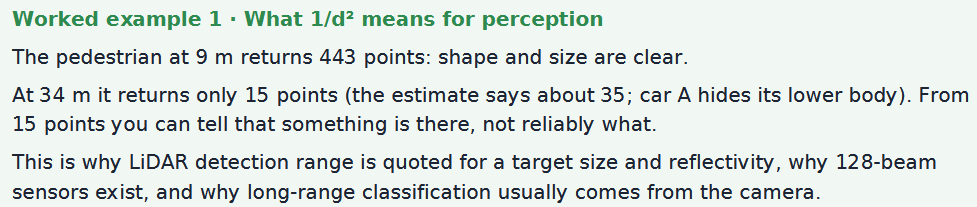

In [1]:
import sys; sys.path.insert(0, "..")          # the notebook runs inside notebooks/
import numpy as np
from src import scene
from src.pointcloud import points_on_target

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)

# 1. rule of thumb vs. simulated scan
print("distance   estimate   simulated")
for lab, dist in [(20, 9), (21, 34)]:
    rows, cols, n = points_on_target(height=1.75, width=0.6, distance=dist)
    print(f"{dist:5d} m   {n:7.0f}    {np.sum(labels == lab):8d}   "
          f"({rows:.1f} beams x {cols:.1f} columns)")

# 2. how much does car A hide? run the same scan without car A
boxes_saved = list(scene.BOXES)
scene.BOXES[:] = [b for b in scene.BOXES if b[0] != 10]      # remove car A (label 10)
_, labels_free, _ = scene.simulate_scan(np.random.default_rng(0))
scene.BOXES[:] = boxes_saved                                  # put it back
print(f"\npedestrian at 34 m without car A in front: {np.sum(labels_free == 21)} points")

# 3. the 1/d^2 law
for d in [10, 20, 40, 80]:
    print(f"pedestrian at {d:2d} m: ~{points_on_target(1.75, 0.6, d)[2]:5.0f} points")

distance   estimate   simulated
    9 m       495         443   (25.9 beams x 19.1 columns)
   34 m        35          15   (6.9 beams x 5.1 columns)

pedestrian at 34 m without car A in front: 34 points
pedestrian at 10 m: ~  401 points
pedestrian at 20 m: ~  100 points
pedestrian at 40 m: ~   25 points
pedestrian at 80 m: ~    6 points


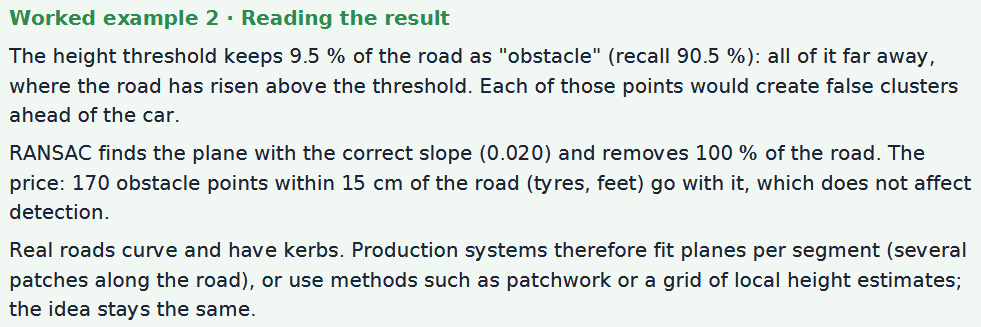

height threshold  recall  90.5%  precision 100.0%  obstacle points removed 0
RANSAC plane      recall 100.0%  precision  99.6%  obstacle points removed 170
RANSAC slope 0.020 (true 0.02), height at the sensor -1.73 m (true -1.73)

road points the threshold calls 'obstacle': 3671, from x = 9.6 m to 46.7 m
expected: the road rises 0.2 m above the sensor's ground level at x = 10 m
obstacle points removed by RANSAC: 170, all lower than 16 cm


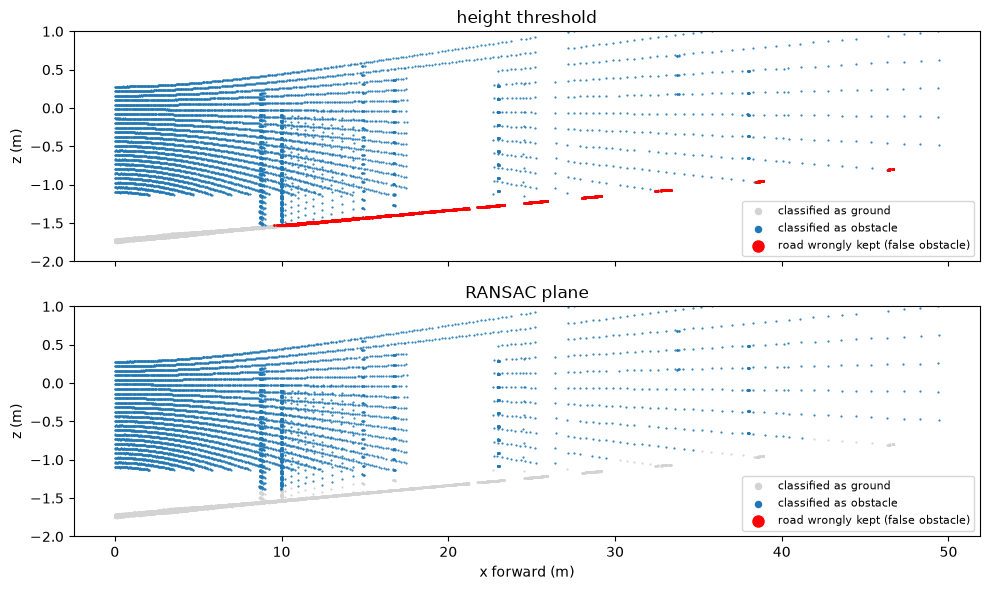

In [2]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src import scene
from src.pointcloud import crop, ransac_plane

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)
roi, roi_mask = crop(cloud)                      # 0-50 m ahead, +-10 m to the side
p = roi[:, :3]
is_ground = labels[roi_mask] == 1                # ground truth from the simulation

# two ground classifiers
ground_naive = p[:, 2] < -scene.SENSOR_HEIGHT + 0.2       # "everything low is ground"
n, d, ground_ransac = ransac_plane(p, threshold=0.15)

def report(name, pred):
    tp = np.sum(pred & is_ground)
    print(f"{name:17s} recall {tp / is_ground.sum():6.1%}  precision {tp / pred.sum():6.1%}  "
          f"obstacle points removed {np.sum(pred & ~is_ground)}")

report("height threshold", ground_naive)
report("RANSAC plane", ground_ransac)
print(f"RANSAC slope {-n[0] / n[2]:.3f} (true {scene.SLOPE}), "
      f"height at the sensor {-d / n[2]:.2f} m (true {-scene.SENSOR_HEIGHT})")

# where does the threshold fail?
missed = is_ground & ~ground_naive
print(f"\nroad points the threshold calls 'obstacle': {missed.sum()}, "
      f"from x = {p[missed, 0].min():.1f} m to {p[missed, 0].max():.1f} m")
x_fail = 0.2 / scene.SLOPE
print(f"expected: the road rises 0.2 m above the sensor's ground level at x = {x_fail:.0f} m")

# which obstacle points does RANSAC remove?
lost = ground_ransac & ~is_ground
h = p[lost, 2] - scene.ground_z(p[lost, 0])
print(f"obstacle points removed by RANSAC: {lost.sum()}, all lower than {h.max() * 100:.0f} cm")

# side view
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for a, pred, title in [(ax[0], ground_naive, "height threshold"),
                       (ax[1], ground_ransac, "RANSAC plane")]:
    a.scatter(p[pred, 0], p[pred, 2], s=0.3, c="lightgrey", label="classified as ground")
    a.scatter(p[~pred, 0], p[~pred, 2], s=0.3, c="tab:blue", label="classified as obstacle")
    a.scatter(p[~pred & is_ground, 0], p[~pred & is_ground, 2], s=1, c="red",
              label="road wrongly kept (false obstacle)")
    a.set_ylim(-2, 1); a.set_ylabel("z (m)"); a.set_title(title)
    a.legend(markerscale=8, fontsize=8)
ax[1].set_xlabel("x forward (m)")
plt.tight_layout(); plt.show()